# Predicting Credit Card Default — An End-to-End Machine Learning Study

| | |
|---|---|
| **Author** | Ramil Imanov |
| **Group** | M666i5 |
| **Dataset** | *Default of Credit Card Clients* — Yeh, I.-C. (2009), UCI Machine Learning Repository, DOI [10.24432/C55S3H](https://doi.org/10.24432/C55S3H) (CC BY 4.0). A CSV copy is included in `data/credit_default.csv`. |
| **Twist** | Imbalance Study (Section 5.1 of the assignment) |

**How to run.** From the repository root:
```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace credit_default_ml.ipynb
```
or open the notebook in Jupyter and choose *Run All*. A full run takes roughly 5–10 minutes on a
laptop. Every figure is written to `figures/` and every table to `results/`; the report quotes
these files. All randomness is controlled by `SEED = 42`.

**Notebook map.** A. Problem definition → B. EDA & preprocessing → C. Baseline → D. Models →
E. Tuning & evaluation → F. Analysis & interpretation → Twist: imbalance study → Final test-set
evaluation (the only time the test set is touched) → G. Conclusion.

In [1]:
# ---------------------------------------------------------------------------
# Setup: imports, global constants, plotting style, small helpers
# ---------------------------------------------------------------------------
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, fbeta_score, make_scorer,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, TunedThresholdClassifierCV,
                                     cross_validate, learning_curve, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
N_JOBS = -1
DATA_PATH = Path("data/credit_default.csv")
FIG_DIR, RES_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

# Business costs (see Section A): approving a future defaulter is ~5x worse than a false alarm.
C_FN, C_FP = 5.0, 1.0

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"No default": "#4C72B0", "Default": "#DD8452"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

SUMMARY = {}  # key numbers collected along the way and saved to results/summary.json


def save_fig(fig, name):
    """Save a figure to figures/<name>.png and show it."""
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


def cost_per_client(y_true, y_pred):
    """Average misclassification cost per client with C_FN for missed defaulters and C_FP for false alarms."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fn = np.sum((y_true == 1) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return (C_FN * fn + C_FP * fp) / len(y_true)


cost_scorer = make_scorer(cost_per_client, greater_is_better=False)
f2_scorer = make_scorer(fbeta_score, beta=2, zero_division=0)

# The same scoring dictionary is used for every model so that comparisons are like-for-like.
SCORING = {
    "ap": "average_precision",      # PR-AUC: primary, threshold-free metric
    "roc_auc": "roc_auc",
    "f1": make_scorer(f1_score, zero_division=0),
    "f2": f2_scorer,
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "bal_acc": "balanced_accuracy",
    "cost": cost_scorer,             # negative cost (higher is better)
}


def threshold_metrics(y_true, proba, thr):
    """All threshold-dependent metrics at a given decision threshold, plus the ranking metrics."""
    pred = (proba >= thr).astype(int)
    return {
        "ap": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "recall": recall_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "bal_acc": balanced_accuracy_score(y_true, pred),
        "cost": cost_per_client(y_true, pred),
        "brier": brier_score_loss(y_true, proba),
    }


print("Ready. Libraries:", {m.__name__: m.__version__ for m in [np, pd, sns, __import__("sklearn"), __import__("imblearn")]})

Ready. Libraries: {'numpy': '2.5.5', 'pandas': '3.1.1', 'seaborn': '0.13.2', 'sklearn': '1.9.1', 'imblearn': '0.14.2'}


## A. Problem definition

**Data.** 30,000 credit-card holders of a Taiwanese bank (April–September 2005). For each client
we know the credit limit, demographics (sex, education, marital status, age), the repayment status
for the last six months (`PAY_1 … PAY_6`: −2 = no consumption, −1 = paid in full, 0 = revolving
credit/minimum paid, 1…8 = months of delay), the six monthly bill statements (`BILL_AMT1 … 6`) and
the six monthly payments (`PAY_AMT1 … 6`), all in NT dollars.

**Task.** *Binary classification: will the client default on the next month's payment
(October 2005)?*

**Why it matters and what a mistake costs.** A bank uses such a score to lower credit limits,
start collection early, or offer a restructuring plan. The two errors are not equally expensive:
* **False negative** (a defaulter predicted as safe): the bank loses part of the outstanding
  balance — typically tens of thousands of NT$.
* **False positive** (a good client flagged): a phone call, a limit review, possibly an annoyed
  customer and some lost interest income — much cheaper.

We therefore assume **C_FN = 5 × C_FP** (a common assumption in the credit-scoring literature;
the exact ratio is a business decision and is varied in the discussion).

**Metric.** About 22 % of clients default, so accuracy is misleading (predicting "no default" for
everyone already gives 78 %). We use
1. **PR-AUC (average precision)** as the *primary, threshold-free* metric for model selection — it
   focuses on the minority (default) class and on how well the model ranks risky clients;
2. **expected cost per client** `(5·FN + 1·FP)/n` to choose the *operating threshold*;
3. ROC-AUC, recall, precision, F1/F2 and balanced accuracy as supporting metrics.

In [2]:
# ---------------------------------------------------------------------------
# Load and clean the data
# ---------------------------------------------------------------------------
raw = pd.read_csv(DATA_PATH)
print("Raw shape:", raw.shape)

df = (raw.drop(columns="ID")
         .rename(columns={"PAY_0": "PAY_1", "default payment next month": "default"}))

# Undocumented category codes are merged into the documented "other" categories.
# These are fixed, data-independent recodings (no statistics are learned), so applying them
# before the train/test split cannot leak information.
print("EDUCATION codes before:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE  codes before:", df["MARRIAGE"].value_counts().sort_index().to_dict())
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})   # 1 grad school, 2 university, 3 high school, 4 other
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})                  # 1 married, 2 single, 3 other

n_dup = df.duplicated().sum()
print(f"Missing values: {df.isna().sum().sum()}, exact duplicate rows: {n_dup}")
# 35 duplicates are kept: with 23 coarse features, two different clients can genuinely share a profile
# (e.g. both with zero bills and zero payments). Removing them would not change any conclusion.

PAY_COLS = [f"PAY_{i}" for i in range(1, 7)]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYAMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]
CAT_COLS = ["SEX", "EDUCATION", "MARRIAGE"]
TARGET = "default"

SUMMARY["n_rows"], SUMMARY["n_features_raw"] = int(len(df)), int(df.shape[1] - 1)
SUMMARY["default_rate"] = float(df[TARGET].mean())
SUMMARY["n_duplicates"] = int(n_dup)
print(f"Default rate: {df[TARGET].mean():.3f}")
df.head()

Raw shape: (30000, 25)
EDUCATION codes before: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE  codes before: {0: 54, 1: 13659, 2: 15964, 3: 323}
Missing values: 0, exact duplicate rows: 35
Default rate: 0.221


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## B. Exploratory analysis

In [3]:
# Summary statistics of the numeric columns
desc = df.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc["skew"] = df.skew()
desc.round(2).to_csv(RES_DIR / "summary_statistics.csv")
desc.round(2)

,mean,std,min,25%,50%,75%,max,skew
LIMIT_BAL,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0,0.99
SEX,1.60,0.49,1.0,1.00,2.0,2.00,2.0,-0.42
EDUCATION,1.84,0.74,1.0,1.00,2.0,2.00,4.0,0.49
MARRIAGE,1.56,0.52,1.0,1.00,2.0,2.00,3.0,0.04
AGE,35.49,9.22,21.0,28.00,34.0,41.00,79.0,0.73
PAY_1,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0,0.73
PAY_2,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0,0.79
PAY_3,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0,0.84
PAY_4,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0,1.00
PAY_5,-0.27,1.13,-2.0,-1.00,0.0,0.00,8.0,1.01


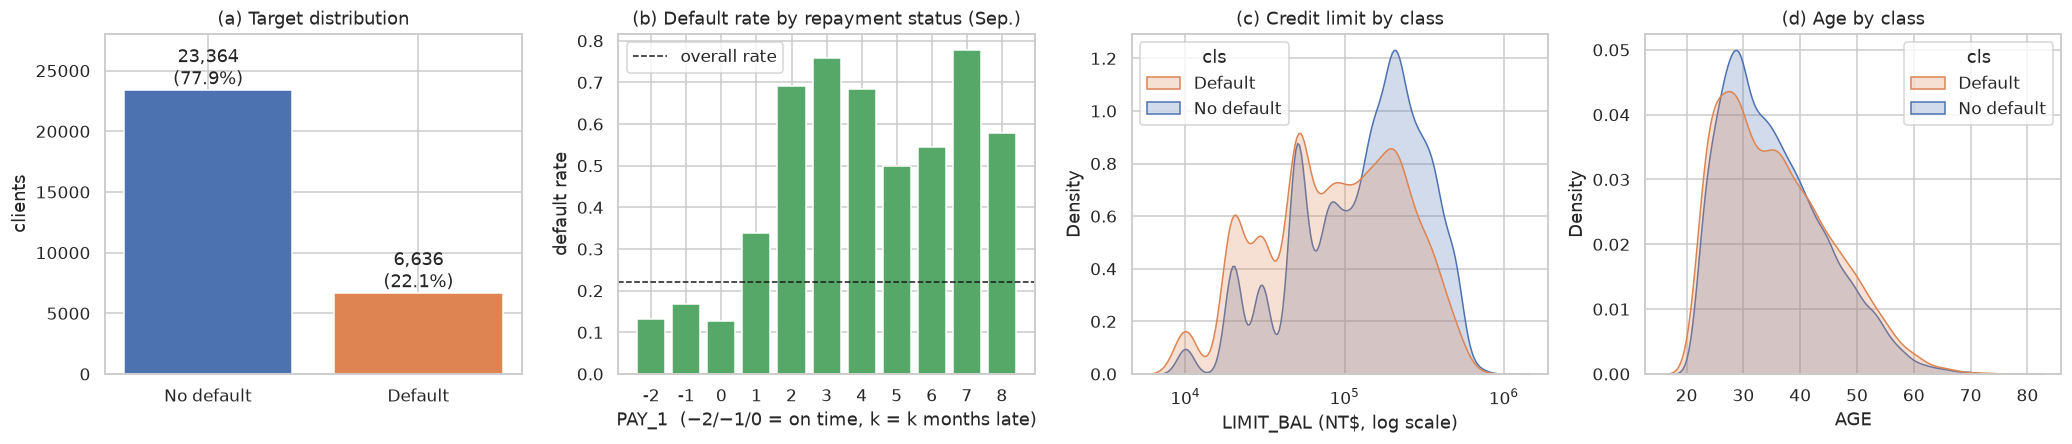

PAY_1        -2        -1          0         1         2        3       4  \
mean      0.132     0.168      0.128     0.339     0.691    0.758   0.684   
size   2759.000  5686.000  14737.000  3688.000  2667.000  322.000  76.000   

PAY_1     5       6      7       8  
mean    0.5   0.545  0.778   0.579  
size   26.0  11.000  9.000  19.000  


In [4]:
# Figure 1: target balance, default rate by most recent repayment status, credit limit by class, age by class
lab = df[TARGET].map({0: "No default", 1: "Default"})
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))

counts = lab.value_counts()[["No default", "Default"]]
axes[0].bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
axes[0].set(title="(a) Target distribution", ylabel="clients", ylim=(0, counts.max() * 1.2))

rate = df.groupby("PAY_1")[TARGET].agg(["mean", "size"])
axes[1].bar(rate.index.astype(str), rate["mean"], color="#55A868")
axes[1].axhline(df[TARGET].mean(), ls="--", c="k", lw=1, label="overall rate")
axes[1].set(title="(b) Default rate by repayment status (Sep.)", xlabel="PAY_1  (−2/−1/0 = on time, k = k months late)",
            ylabel="default rate")
axes[1].legend()

sns.kdeplot(data=df.assign(cls=lab), x="LIMIT_BAL", hue="cls", palette=PALETTE, common_norm=False,
            log_scale=True, fill=True, ax=axes[2])
axes[2].set(title="(c) Credit limit by class", xlabel="LIMIT_BAL (NT$, log scale)")

sns.kdeplot(data=df.assign(cls=lab), x="AGE", hue="cls", palette=PALETTE, common_norm=False,
            fill=True, ax=axes[3])
axes[3].set(title="(d) Age by class")
fig.tight_layout()
save_fig(fig, "fig01_eda_overview")
print(rate.round(3).T)

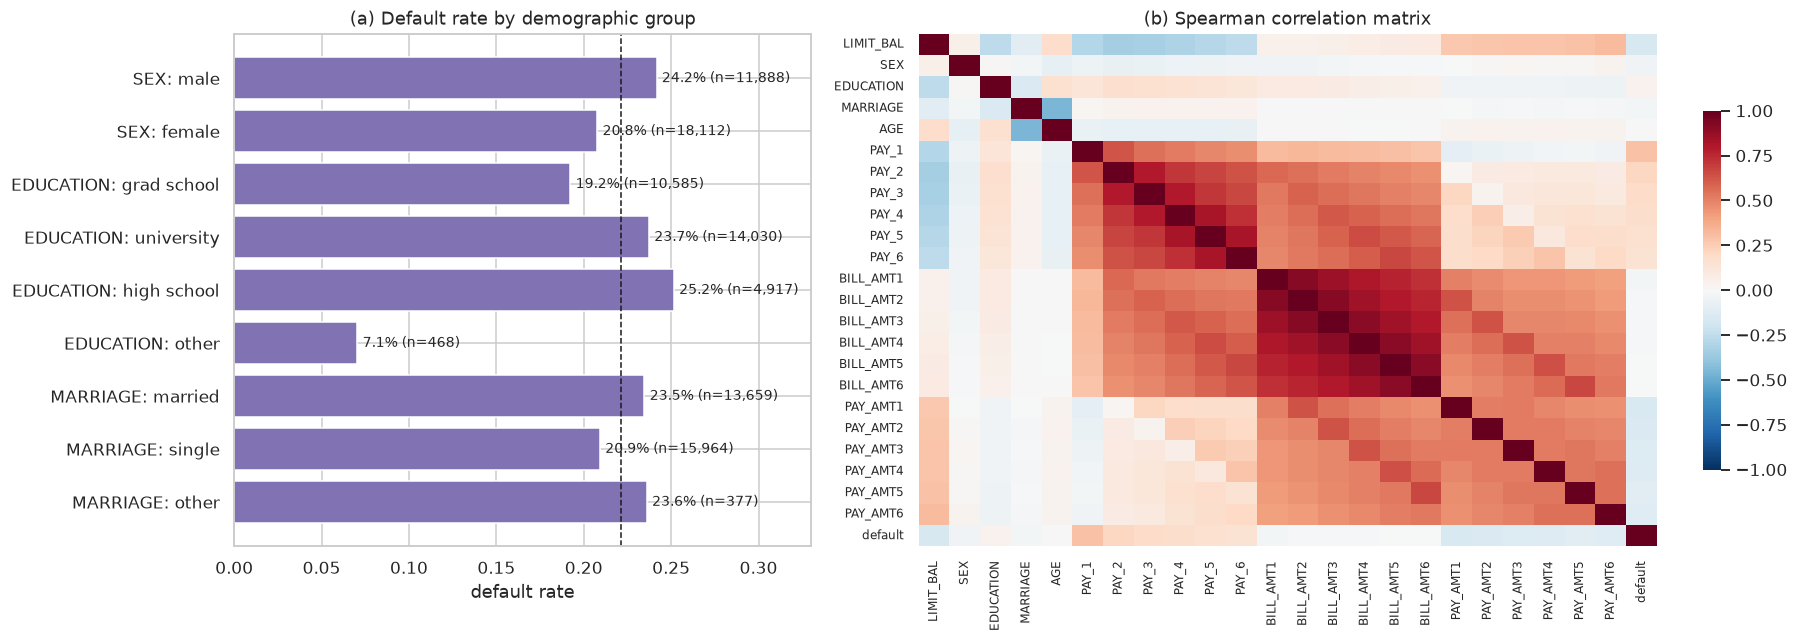

Strongest Spearman correlations with the target:
 PAY_1        0.292
PAY_2        0.217
PAY_3        0.195
PAY_4        0.174
LIMIT_BAL   -0.170
PAY_AMT1    -0.160
PAY_5        0.159
PAY_AMT2    -0.151
Name: default, dtype: float64


In [5]:
# Figure 2: default rate by demographic group, and the correlation structure
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.6]})
names = {"SEX": {1: "male", 2: "female"},
         "EDUCATION": {1: "grad school", 2: "university", 3: "high school", 4: "other"},
         "MARRIAGE": {1: "married", 2: "single", 3: "other"}}
rows = []
for col, mp in names.items():
    g = df.groupby(col)[TARGET].agg(["mean", "size"])
    for k, r in g.iterrows():
        rows.append({"group": f"{col}: {mp[k]}", "rate": r["mean"], "n": int(r["size"])})
grp = pd.DataFrame(rows)
axes[0].barh(grp["group"], grp["rate"], color="#8172B3")
axes[0].axvline(df[TARGET].mean(), ls="--", c="k", lw=1)
for i, (r, n) in enumerate(zip(grp["rate"], grp["n"])):
    axes[0].text(r + 0.003, i, f"{r:.1%} (n={n:,})", va="center", fontsize=9)
axes[0].invert_yaxis()
axes[0].set(title="(a) Default rate by demographic group", xlabel="default rate", xlim=(0, 0.33))

corr = df.corr(method="spearman")
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1], cbar_kws={"shrink": .7},
            xticklabels=True, yticklabels=True)
axes[1].set_title("(b) Spearman correlation matrix")
axes[1].tick_params(labelsize=8)
fig.tight_layout()
save_fig(fig, "fig02_eda_groups_corr")

top_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Strongest Spearman correlations with the target:\n", top_corr.head(8).round(3))
SUMMARY["top_corr"] = top_corr.head(8).round(3).to_dict()

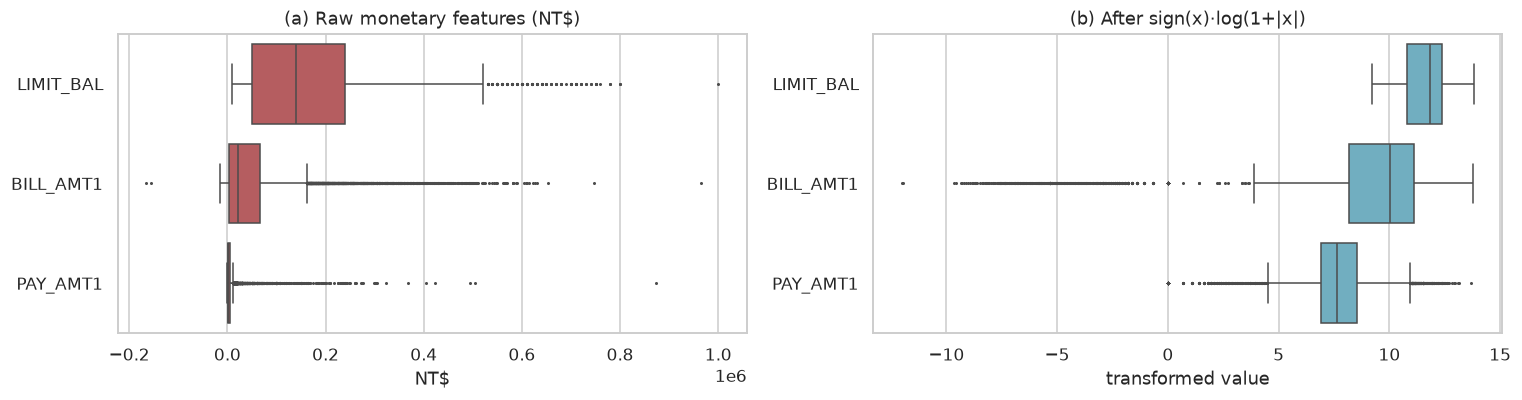

Share of negative bill amounts (credit balances): {'BILL_AMT1': 0.02, 'BILL_AMT2': 0.022, 'BILL_AMT3': 0.022, 'BILL_AMT4': 0.022, 'BILL_AMT5': 0.022, 'BILL_AMT6': 0.023}
Clients whose Sept. bill exceeds their limit: 7.0%


In [6]:
# Figure 3: heavy tails / outliers in the monetary features, before and after a signed log transform
money = ["LIMIT_BAL"] + BILL_COLS[:1] + PAYAMT_COLS[:1]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.boxplot(data=df[money], orient="h", ax=axes[0], color="#C44E52", fliersize=1)
axes[0].set(title="(a) Raw monetary features (NT$)", xlabel="NT$")
signed_log = lambda x: np.sign(x) * np.log1p(np.abs(x))
sns.boxplot(data=signed_log(df[money]), orient="h", ax=axes[1], color="#64B5CD", fliersize=1)
axes[1].set(title="(b) After sign(x)·log(1+|x|)", xlabel="transformed value")
fig.tight_layout()
save_fig(fig, "fig03_outliers")
print("Share of negative bill amounts (credit balances):", (df[BILL_COLS] < 0).mean().round(3).to_dict())
print("Clients whose Sept. bill exceeds their limit:", f"{(df.BILL_AMT1 > df.LIMIT_BAL).mean():.1%}")

**Findings.**
* No missing values. Two categorical columns contain undocumented codes, which we merged into "other".
* The target is moderately imbalanced: 22.1 % defaults.
* **Repayment status is by far the strongest signal.** Clients one month late in September already
  default about 34 % of the time, and those two or more months late default about 70 % of the time,
  compared with 12–17 % for clients who are on time (Fig. 1b). The six `PAY_k` columns are strongly
  correlated with each other (Fig. 2b).
* Clients with lower credit limits default more often (Fig. 1c). Age has a weak U-shaped effect: the default rate is lowest at ages 25–35 (≈ 19–20 %) and about 27 % below 25 and above 60.
  Demographic differences are small (Fig. 2a).
* The six bill amounts are strongly correlated with each other (Spearman ρ ≥ 0.73). Payment amounts are only weakly related to the target.
* Monetary features are extremely right-skewed, with long tails of large but genuine values
  (Fig. 3a). Some bills are negative, meaning the client is in credit. These values are **not errors**,
  so we do not delete them. Instead we compress them with a signed log transform (Fig. 3b), which
  keeps the sign and order but stops a few huge balances from dominating distance-based models
  (kNN) and linear models.

### Feature engineering and the train / validation / test split

We add five row-wise features that a credit analyst would look at. Each one uses only the client's
own row and fixed constants, so none of them can leak information across clients:
* `MAX_DELAY` is the worst delay over the six months, and `N_DELAYS` is the number of months the client was late.
* `AVG_UTIL` is the mean bill divided by the credit limit, clipped to [−1, 3].
* `PAY_RATIO` is the total paid divided by the total billed, clipped to [0, 5].
* `LAST_PAY_RATIO` is the September payment divided by the August bill, clipped to [0, 5].

We then split the data once into **70 % train, 15 % validation and 15 % test**, stratified on the
target, with `SEED = 42`.
* **Train:** cross-validation and hyperparameter tuning.
* **Validation:** model checks, threshold selection and error analysis.
* **Test:** locked away until the very last section.

In [7]:
def add_features(d):
    d = d.copy()
    d["MAX_DELAY"] = d[PAY_COLS].max(axis=1)
    d["N_DELAYS"] = (d[PAY_COLS] > 0).sum(axis=1)
    d["AVG_UTIL"] = (d[BILL_COLS].mean(axis=1) / d["LIMIT_BAL"]).clip(-1, 3)
    d["PAY_RATIO"] = (d[PAYAMT_COLS].sum(axis=1) / d[BILL_COLS].sum(axis=1).clip(lower=1)).clip(0, 5)
    d["LAST_PAY_RATIO"] = (d["PAY_AMT1"] / d["BILL_AMT2"].clip(lower=1)).clip(0, 5)
    return d


X_all = add_features(df.drop(columns=TARGET))
y_all = df[TARGET].values

X_trval, X_test, y_trval, y_test = train_test_split(X_all, y_all, test_size=0.15, stratify=y_all, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.15 / 0.85, stratify=y_trval,
                                                  random_state=SEED)
for name, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:>10}: {len(yy):6,d} rows, default rate {yy.mean():.3f}")
SUMMARY["split_sizes"] = {"train": len(y_train), "val": len(y_val), "test": len(y_test)}

# One CV splitter shared by EVERY model → identical folds, fair comparison
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

     train: 21,000 rows, default rate 0.221
validation:  4,500 rows, default rate 0.221
      test:  4,500 rows, default rate 0.221


### Preprocessing pipeline

All preprocessing is placed inside a scikit-learn `Pipeline`. During cross-validation the pipeline
is re-fitted on each training fold, so the scaler, the feature selector and any resampler never see
the held-out fold, the validation set or the test set.

| Columns | Treatment | Why |
|---|---|---|
| `LIMIT_BAL`, `BILL_AMT*`, `PAY_AMT*` | signed log1p → standardise | heavy tails and outliers (Fig. 3) |
| `PAY_*`, `MAX_DELAY`, `N_DELAYS` | standardise, kept as ordinal numbers | the codes are ordered (more delay means more risk) |
| `AGE`, `AVG_UTIL`, `PAY_RATIO`, `LAST_PAY_RATIO` | standardise | the ratios are already clipped |
| `SEX`, `EDUCATION`, `MARRIAGE` | one-hot encode | nominal categories |

Scaling does not change trees, but it is essential for kNN, logistic regression and Naive Bayes.
Using one preprocessing block for every model keeps the comparison fair. For kNN and Naive Bayes
we also tune **univariate feature selection** (`SelectKBest`, ANOVA F-test) inside the pipeline.
Both models suffer from many redundant features: kNN through distance dilution, Naive Bayes
because it assumes the features are independent.

In [8]:
MONEY_COLS = ["LIMIT_BAL"] + BILL_COLS + PAYAMT_COLS
ORD_COLS = PAY_COLS + ["MAX_DELAY", "N_DELAYS"]
OTHER_NUM = ["AGE", "AVG_UTIL", "PAY_RATIO", "LAST_PAY_RATIO"]


def make_preprocessor():
    return ColumnTransformer([
        ("money", Pipeline([("slog", FunctionTransformer(signed_log, feature_names_out="one-to-one")),
                            ("scale", StandardScaler())]), MONEY_COLS),
        ("ord", StandardScaler(), ORD_COLS),
        ("num", StandardScaler(), OTHER_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ], verbose_feature_names_out=False)


prep_demo = make_preprocessor().fit(X_train)
FEATURE_NAMES = list(prep_demo.get_feature_names_out())
print(f"{len(FEATURE_NAMES)} model features after preprocessing:", FEATURE_NAMES)

34 model features after preprocessing: ['LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'MAX_DELAY', 'N_DELAYS', 'AGE', 'AVG_UTIL', 'PAY_RATIO', 'LAST_PAY_RATIO', 'SEX_1', 'SEX_2', 'EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']


## C. Baseline

We use two reference points. Both are evaluated with the same 5-fold cross-validation on the
training set as every later model.
* A **dummy classifier** that predicts the class prior. Its PR-AUC equals the default rate (≈ 0.22).
* A **plain logistic regression** with default settings and no tuning.

In [9]:
def cv_summary(estimator, X, y, cv=CV, scoring=SCORING):
    """Cross-validate and return (mean/std table, raw fold scores)."""
    res = cross_validate(estimator, X, y, cv=cv, scoring=scoring, n_jobs=N_JOBS, return_train_score=False)
    out = {}
    for k in scoring:
        s = res[f"test_{k}"] * (-1 if k == "cost" else 1)
        out[f"{k}_mean"], out[f"{k}_std"] = s.mean(), s.std()
    out["fit_time_s"] = res["fit_time"].mean()
    return out, res


baselines = {
    "Dummy (prior)": Pipeline([("prep", make_preprocessor()), ("clf", DummyClassifier(strategy="prior"))]),
    "Logistic regression (default)": Pipeline([("prep", make_preprocessor()),
                                               ("clf", LogisticRegression(max_iter=2000))]),
}
base_rows = {}
for name, est in baselines.items():
    base_rows[name], _ = cv_summary(est, X_train, y_train)
base_df = pd.DataFrame(base_rows).T
base_df.round(4).to_csv(RES_DIR / "baseline_cv.csv")
SUMMARY["baseline"] = base_df.round(4).to_dict(orient="index")
base_df[["ap_mean", "ap_std", "roc_auc_mean", "roc_auc_std", "recall_mean", "f1_mean", "cost_mean"]].round(3)

,ap_mean,ap_std,roc_auc_mean,roc_auc_std,recall_mean,f1_mean,cost_mean
Dummy (prior),0.221,0.000,0.500,0.00,0.000,0.000,1.106
Logistic regression (default),0.506,0.012,0.759,0.01,0.299,0.408,0.812


The dummy model scores PR-AUC ≈ 0.22, ROC-AUC = 0.5 and recall 0. Its cost is about 1.1 per client,
because it misses every defaulter. Plain logistic regression already ranks clients far better than
chance. However, at the default threshold of 0.5 it catches only about a third of the defaulters,
which is a first sign that the threshold will matter (see the Twist section).

## D. Models

We compare **six model families**. All of them share the same preprocessing, the same CV folds and
the same tuning budget.

| Model | Why it is a reasonable candidate | Assumptions this data may violate |
|---|---|---|
| **Regularised logistic regression** (elastic net) | interpretable coefficients, well-calibrated probabilities, the industry standard for credit scoring | assumes the log-odds are linear in the features, but the effect of `PAY_*` is step-like (Fig. 1b); the bills are highly collinear (regularisation helps) |
| **k-nearest neighbours** | non-parametric, so it can capture local patterns such as "similar clients default together" | assumes distance is meaningful, which breaks down with 32 mixed-type features of very different relevance (hence the tuned feature selection); slow at prediction time |
| **Gaussian Naive Bayes** | very fast, a strong baseline with few parameters | features are assumed independent given the class (strongly violated: the six `PAY_k` and the six bills are near-duplicates) and Gaussian (the features are skewed and discrete) |
| **Decision tree** | handles the step-like effects of delay codes, readable rules | high variance; axis-aligned splits |
| **Random forest** | reduces the variance of trees by bagging, robust to scaling and outliers | little to violate; correlated features split the importance between them |
| **Gradient boosting** (`HistGradientBoosting`) | usually the strongest model on tabular data, captures interactions | can overfit if not regularised; less interpretable |

We left out SVMs. A kernel SVM scales roughly quadratically with the 21k training rows, so 100
tuning fits would be far slower than for the other families without adding a different kind of
model. Logistic regression already covers the linear-margin case.

## E. Tuning and evaluation

Every model is tuned with **randomized search over 20 configurations** (the full grid when it is
smaller) using the shared 5-fold stratified CV on the training set. The search optimises PR-AUC.
For the best configuration we report the **mean ± standard deviation across the 5 folds** of every
metric.

In [10]:
def pipe(clf, select=False):
    steps = [("prep", make_preprocessor())]
    if select:
        steps.append(("select", SelectKBest(f_classif)))
    steps.append(("clf", clf))
    return Pipeline(steps)


MODELS = {
    "Logistic regression": (
        pipe(LogisticRegression(solver="saga", max_iter=3000, random_state=SEED)),
        {"clf__C": loguniform(1e-3, 1e2), "clf__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]}),
    "k-NN": (
        pipe(KNeighborsClassifier(), select=True),
        {"select__k": [8, 12, 16, 24, "all"], "clf__n_neighbors": [11, 25, 51, 75, 101, 151, 201],
         "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}),
    "Naive Bayes": (
        pipe(GaussianNB(), select=True),
        {"select__k": [3, 5, 8, 12, 16, 24, "all"], "clf__var_smoothing": np.logspace(-11, -1, 11)}),
    "Decision tree": (
        pipe(DecisionTreeClassifier(random_state=SEED)),
        {"clf__max_depth": [3, 4, 5, 6, 8, 10, 12, None], "clf__min_samples_leaf": [1, 10, 25, 50, 100, 200],
         "clf__criterion": ["gini", "entropy"]}),
    "Random forest": (
        pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)),
        {"clf__max_depth": [6, 8, 10, 14, None], "clf__min_samples_leaf": [1, 5, 10, 25, 50],
         "clf__max_features": ["sqrt", 0.3, 0.5]}),
    "Gradient boosting": (
        pipe(HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                            n_iter_no_change=20, random_state=SEED)),
        {"clf__learning_rate": loguniform(0.01, 0.3), "clf__max_leaf_nodes": [7, 15, 31, 63],
         "clf__min_samples_leaf": [20, 50, 100, 200], "clf__l2_regularization": loguniform(1e-3, 10)}),
}

searches, tune_rows, fold_scores = {}, {}, {}
for name, (est, space) in MODELS.items():
    t0 = time.time()
    search = RandomizedSearchCV(est, space, n_iter=20, scoring=SCORING, refit="ap", cv=CV,
                                n_jobs=N_JOBS, random_state=SEED)
    search.fit(X_train, y_train)
    i = search.best_index_
    cvr = search.cv_results_
    row = {}
    for k in SCORING:
        sign = -1 if k == "cost" else 1
        row[f"{k}_mean"], row[f"{k}_std"] = sign * cvr[f"mean_test_{k}"][i], cvr[f"std_test_{k}"][i]
    row["fit_time_s"] = cvr["mean_fit_time"][i]
    row["search_time_s"] = time.time() - t0
    row["best_params"] = {k.replace("clf__", "").replace("select__", "select_"): (v if not isinstance(v, (np.floating, float)) else float(f"{v:.4g}"))
                          for k, v in search.best_params_.items()}
    fold_scores[name] = [cvr[f"split{f}_test_ap"][i] for f in range(CV.get_n_splits())]
    searches[name], tune_rows[name] = search, row
    print(f"{name:<20} AP = {row['ap_mean']:.4f} ± {row['ap_std']:.4f}   ({row['search_time_s']:.0f}s)  {row['best_params']}")

tune_df = pd.DataFrame(tune_rows).T
tune_df.to_csv(RES_DIR / "model_comparison_cv.csv")

Logistic regression  AP = 0.5065 ± 0.0124   (36s)  {'C': 0.1978, 'l1_ratio': 1.0}


k-NN                 AP = 0.5270 ± 0.0198   (19s)  {'select_k': 12, 'weights': 'uniform', 'p': 1, 'n_neighbors': 101}


Naive Bayes          AP = 0.4968 ± 0.0150   (2s)  {'select_k': 24, 'var_smoothing': 1e-07}


Decision tree        AP = 0.5346 ± 0.0180   (3s)  {'min_samples_leaf': 200, 'max_depth': 8, 'criterion': 'entropy'}


Random forest        AP = 0.5603 ± 0.0195   (126s)  {'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 10}


Gradient boosting    AP = 0.5597 ± 0.0198   (16s)  {'l2_regularization': 0.2481, 'learning_rate': 0.017, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}


In [11]:
# Combined table: baselines + tuned models (CV on training set, mean ± std over 5 folds, threshold 0.5)
cols = ["ap", "roc_auc", "recall", "precision", "f1", "bal_acc", "cost"]
comp = pd.concat([base_df, tune_df.drop(columns=["best_params", "search_time_s"])])
pretty = pd.DataFrame({c: [f"{m:.3f} ± {s:.3f}" for m, s in zip(comp[f"{c}_mean"].astype(float), comp[f"{c}_std"].astype(float))]
                       for c in cols}, index=comp.index)
pretty["fit time (s)"] = comp["fit_time_s"].astype(float).round(2)
pretty.to_csv(RES_DIR / "model_comparison_pretty.csv")
SUMMARY["cv_comparison"] = {n: {c: [round(float(comp.loc[n, f"{c}_mean"]), 4), round(float(comp.loc[n, f"{c}_std"]), 4)]
                                for c in cols} | {"fit_time_s": round(float(comp.loc[n, "fit_time_s"]), 2)}
                            for n in comp.index}
SUMMARY["best_params"] = {n: tune_rows[n]["best_params"] for n in tune_rows}
pretty

,ap,roc_auc,recall,precision,f1,bal_acc,cost,fit time (s)
Dummy (prior),0.221 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,1.106 ± 0.000,0.05
Logistic regression (default),0.506 ± 0.012,0.759 ± 0.010,0.299 ± 0.011,0.640 ± 0.021,0.408 ± 0.013,0.626 ± 0.006,0.812 ± 0.013,0.10
Logistic regression,0.507 ± 0.012,0.759 ± 0.010,0.297 ± 0.009,0.644 ± 0.021,0.406 ± 0.012,0.625 ± 0.005,0.814 ± 0.012,1.02
k-NN,0.527 ± 0.020,0.771 ± 0.012,0.367 ± 0.010,0.639 ± 0.029,0.466 ± 0.015,0.654 ± 0.007,0.746 ± 0.015,0.10
Naive Bayes,0.497 ± 0.015,0.752 ± 0.007,0.542 ± 0.009,0.481 ± 0.012,0.510 ± 0.010,0.688 ± 0.007,0.636 ± 0.013,0.12
Decision tree,0.535 ± 0.018,0.771 ± 0.011,0.347 ± 0.018,0.665 ± 0.034,0.455 ± 0.013,0.648 ± 0.007,0.762 ± 0.016,0.32
Random forest,0.560 ± 0.019,0.783 ± 0.011,0.353 ± 0.010,0.668 ± 0.027,0.462 ± 0.012,0.652 ± 0.006,0.754 ± 0.012,18.75
Gradient boosting,0.560 ± 0.020,0.785 ± 0.012,0.352 ± 0.012,0.673 ± 0.029,0.462 ± 0.014,0.651 ± 0.007,0.755 ± 0.015,2.94


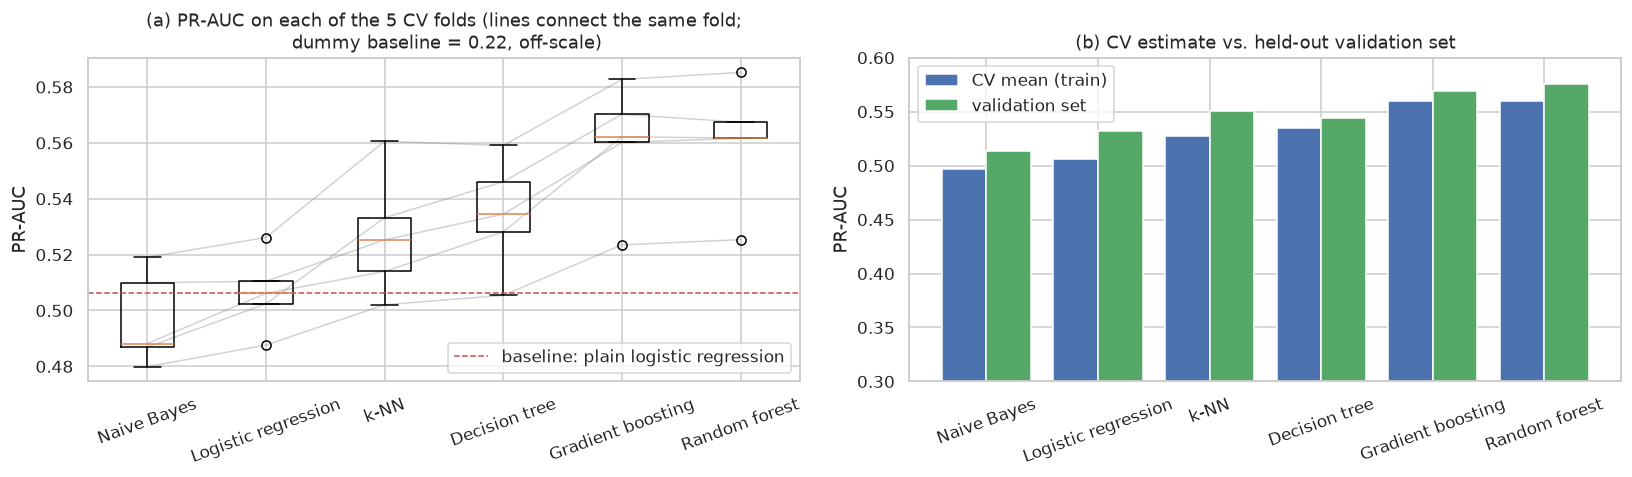

Highest CV PR-AUC: Random forest. Tied within 1 std: ['Random forest', 'Gradient boosting']. Selected (fastest of the tied): Gradient boosting
  paired fold differences Gradient boosting − Random forest: [-0.0015  0.0004 -0.0025  0.0028 -0.0019] (mean -0.0005)


,val_ap,val_roc_auc,cv_ap_mean
Logistic regression,0.5323,0.7667,0.5065
k-NN,0.5506,0.7749,0.5270
Naive Bayes,0.5135,0.7534,0.4968
Decision tree,0.5437,0.7699,0.5346
Random forest,0.5752,0.7861,0.5603
Gradient boosting,0.5689,0.7880,0.5597


In [12]:
# Figure 4: per-fold PR-AUC of every tuned model (same folds → paired comparison) + validation-set check
val_rows = {}
for name, s in searches.items():
    p = s.best_estimator_.predict_proba(X_val)[:, 1]
    val_rows[name] = {"val_ap": average_precision_score(y_val, p), "val_roc_auc": roc_auc_score(y_val, p)}
val_df = pd.DataFrame(val_rows).T
val_df["cv_ap_mean"] = tune_df["ap_mean"].astype(float)
val_df.round(4).to_csv(RES_DIR / "validation_check.csv")
SUMMARY["validation_check"] = val_df.round(4).to_dict(orient="index")

order = tune_df["ap_mean"].astype(float).sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
fs = pd.DataFrame(fold_scores)[order]
for j in range(len(fs)):
    axes[0].plot(range(len(order)), fs.iloc[j].values, c="grey", alpha=.35, lw=1)
axes[0].boxplot(fs.values, positions=range(len(order)), widths=.45)
axes[0].axhline(base_df.loc["Logistic regression (default)", "ap_mean"], c="#C44E52", ls="--", lw=1,
                label="baseline: plain logistic regression")
axes[0].set_xticks(range(len(order)), order, rotation=20)
axes[0].set(title="(a) PR-AUC on each of the 5 CV folds (lines connect the same fold;\n dummy baseline = 0.22, off-scale)", ylabel="PR-AUC")
axes[0].legend(loc="lower right")

x = np.arange(len(order))
axes[1].bar(x - .2, val_df.loc[order, "cv_ap_mean"], .4, label="CV mean (train)", color="#4C72B0")
axes[1].bar(x + .2, val_df.loc[order, "val_ap"], .4, label="validation set", color="#55A868")
axes[1].set_xticks(x, order, rotation=20)
axes[1].set(title="(b) CV estimate vs. held-out validation set", ylabel="PR-AUC", ylim=(0.3, 0.6))
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig04_model_comparison")

# Model selection rule (fixed before looking at validation/test):
#   1. take every model whose CV PR-AUC is within one fold-std of the top model ("statistically tied");
#   2. among those, pick the one that is cheapest to train (stability + cost criterion).
ap_mean, ap_std = tune_df["ap_mean"].astype(float), tune_df["ap_std"].astype(float)
top = ap_mean.idxmax()
tied = ap_mean[ap_mean >= ap_mean[top] - ap_std[top]].index.tolist()
best_name = tune_df.loc[tied, "fit_time_s"].astype(float).idxmin()
others = [m for m in tied if m != best_name]
print(f"Highest CV PR-AUC: {top}. Tied within 1 std: {tied}. Selected (fastest of the tied): {best_name}")
for o in others:
    diff = np.array(fold_scores[best_name]) - np.array(fold_scores[o])
    print(f"  paired fold differences {best_name} − {o}: {np.round(diff, 4)} (mean {diff.mean():+.4f})")
    SUMMARY[f"fold_diff_vs_{o}"] = diff.round(4).tolist()
SUMMARY["top_cv_model"], SUMMARY["tied_models"], SUMMARY["best_model"] = top, tied, best_name
val_df.round(4)

**Interpretation.**
* **The two ensembles rank clients best and are tied.** Random forest and gradient boosting both
  reach PR-AUC ≈ 0.56, compared with 0.51 for the logistic-regression baseline and 0.22 for the dummy.
* **The gaps between the other models are smaller than the fold-to-fold noise.** The decision tree
  and k-NN come next (≈ 0.53). Naive Bayes is last (≈ 0.50) because the near-duplicate `PAY_k` and
  bill columns break its independence assumption.
* **Tuning did not help logistic regression.** The tuned model is no better than the default one.
  With about 21k rows and 32 features there is little variance for regularisation to remove. Its
  limitation is *bias*: a linear model cannot represent the step-like effect of the delay codes.
* **Fold standard deviations (≈ 0.01–0.02) are as large as the gap between the two ensembles.** For
  that reason the selection rule treats models within one std of the best as tied and picks the
  cheapest to train: **gradient boosting**, about 7× faster than the random forest.
* The validation-set scores (Fig. 4b) agree with the CV estimates, so the tuning did not overfit
  the CV folds.

### Choosing the operating threshold (validation set)

The tuned models output probabilities, and a decision needs a threshold. Following Section A, we
pick the threshold that **minimises the expected cost** `(5·FN + FP)/n` on the validation set
(never the test set). For perfectly calibrated probabilities, decision theory gives
t* = C_FP / (C_FP + C_FN) = 1/6 ≈ 0.167, so we expect a value close to that.

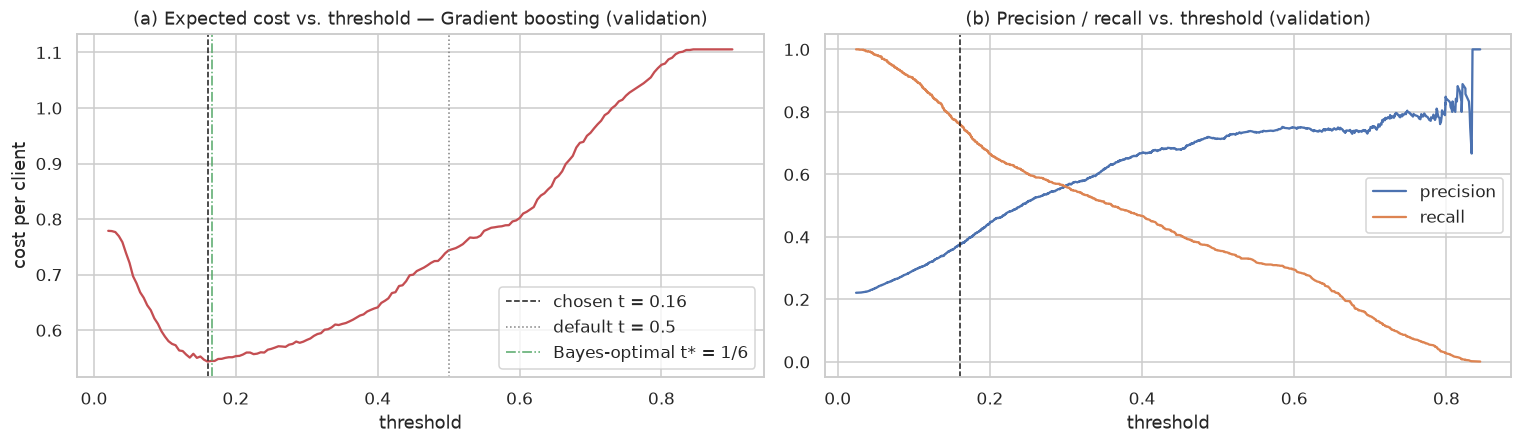

,t = 0.5,t = 0.16
ap,0.569,0.569
roc_auc,0.788,0.788
recall,0.356,0.762
precision,0.714,0.375
f1,0.475,0.503
f2,0.395,0.632
bal_acc,0.658,0.701
cost,0.744,0.544
brier,0.131,0.131


In [13]:
best_model = searches[best_name].best_estimator_
p_val = best_model.predict_proba(X_val)[:, 1]
thr_grid = np.linspace(0.02, 0.9, 177)
val_cost = np.array([cost_per_client(y_val, (p_val >= t).astype(int)) for t in thr_grid])
best_thr = float(thr_grid[val_cost.argmin()])
SUMMARY["chosen_threshold"] = round(best_thr, 3)
SUMMARY["val_at_05"] = {k: round(v, 4) for k, v in threshold_metrics(y_val, p_val, 0.5).items()}
SUMMARY["val_at_best_thr"] = {k: round(v, 4) for k, v in threshold_metrics(y_val, p_val, best_thr).items()}

prec, rec, thr_pr = precision_recall_curve(y_val, p_val)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(thr_grid, val_cost, c="#C44E52")
axes[0].axvline(best_thr, c="k", ls="--", lw=1, label=f"chosen t = {best_thr:.2f}")
axes[0].axvline(0.5, c="grey", ls=":", lw=1, label="default t = 0.5")
axes[0].axvline(1 / 6, c="#55A868", ls="-.", lw=1, label="Bayes-optimal t* = 1/6")
axes[0].set(title=f"(a) Expected cost vs. threshold — {best_name} (validation)", xlabel="threshold",
            ylabel="cost per client")
axes[0].legend()
axes[1].plot(thr_pr, prec[:-1], label="precision")
axes[1].plot(thr_pr, rec[:-1], label="recall")
axes[1].axvline(best_thr, c="k", ls="--", lw=1)
axes[1].set(title="(b) Precision / recall vs. threshold (validation)", xlabel="threshold")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig05_threshold")
pd.DataFrame({"t = 0.5": SUMMARY["val_at_05"], f"t = {best_thr:.2f}": SUMMARY["val_at_best_thr"]}).round(3)

## F. Analysis and interpretation

### Learning curves: bias, variance and whether more data would help

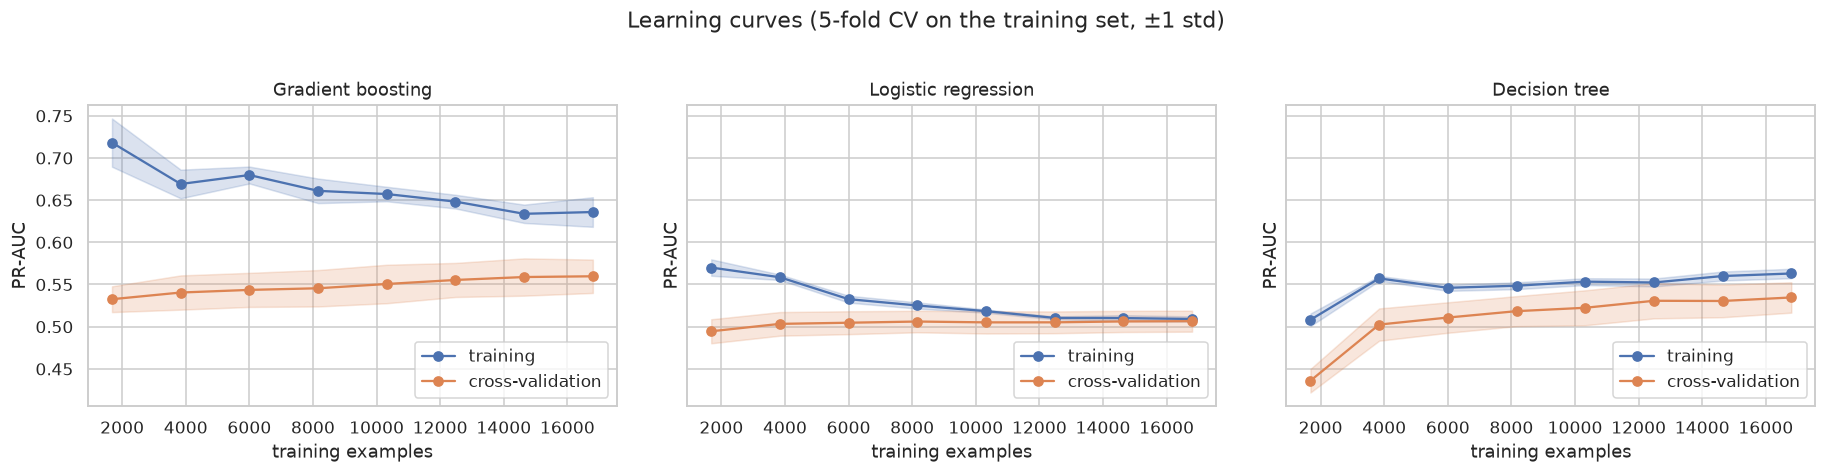

,train_end,cv_end,cv_start,gap_end,cv_last_two_delta
Gradient boosting,0.6359,0.5597,0.5326,0.0761,0.0009
Logistic regression,0.5091,0.5065,0.4946,0.0026,0.0003
Decision tree,0.5630,0.5346,0.4360,0.0284,0.0042


In [14]:
lc_models = {best_name: best_model,
             "Logistic regression": searches["Logistic regression"].best_estimator_,
             "Decision tree": searches["Decision tree"].best_estimator_}
fig, axes = plt.subplots(1, len(lc_models), figsize=(17, 4.2), sharey=True)
lc_summary = {}
for ax, (name, est) in zip(axes, lc_models.items()):
    sizes, tr, te = learning_curve(est, X_train, y_train, cv=CV, scoring="average_precision",
                                   train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=N_JOBS)
    for sc, lbl, c in [(tr, "training", "#4C72B0"), (te, "cross-validation", "#DD8452")]:
        ax.plot(sizes, sc.mean(1), "o-", c=c, label=lbl)
        ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=c, alpha=.2)
    ax.set(title=name, xlabel="training examples", ylabel="PR-AUC")
    ax.legend(loc="lower right")
    lc_summary[name] = {"train_end": round(float(tr.mean(1)[-1]), 4), "cv_end": round(float(te.mean(1)[-1]), 4),
                        "cv_start": round(float(te.mean(1)[0]), 4), "gap_end": round(float(tr.mean(1)[-1] - te.mean(1)[-1]), 4),
                        "cv_last_two_delta": round(float(te.mean(1)[-1] - te.mean(1)[-2]), 4)}
fig.suptitle("Learning curves (5-fold CV on the training set, ±1 std)", y=1.02)
fig.tight_layout()
save_fig(fig, "fig06_learning_curves")
SUMMARY["learning_curves"] = lc_summary
pd.DataFrame(lc_summary).T

**Reading the learning curves.**
* **Logistic regression** has almost no gap between training and CV PR-AUC (≈ 0.51 vs 0.51), and the
  curve is flat. This is classic **high bias**: the linear model is too simple, and more data will
  not help. Only a more flexible model or better features will.
* **Gradient boosting** has a moderate gap (≈ 0.64 vs 0.56), which means some **variance**. Its CV
  curve rose from 0.53 to 0.56 but has practically stopped rising: the last step added < 0.001.
  More rows of the *same* kind of data would bring at best small gains.
* The **decision tree** improves the most with data (0.44 → 0.53) and is still rising slowly.

All three curves are levelling off below 0.6. Together with the error analysis below, this points
to the **information in the features** as the main limit, not the amount of data.

### Feature importance: does the model use sensible evidence?

We compute **permutation importance** on the validation set: how much PR-AUC drops when one column
is shuffled. Because we permute the *original* columns through the whole pipeline, the result can
be read in terms of the raw features. Next to it we show the **standardised coefficients** of the
tuned logistic regression.

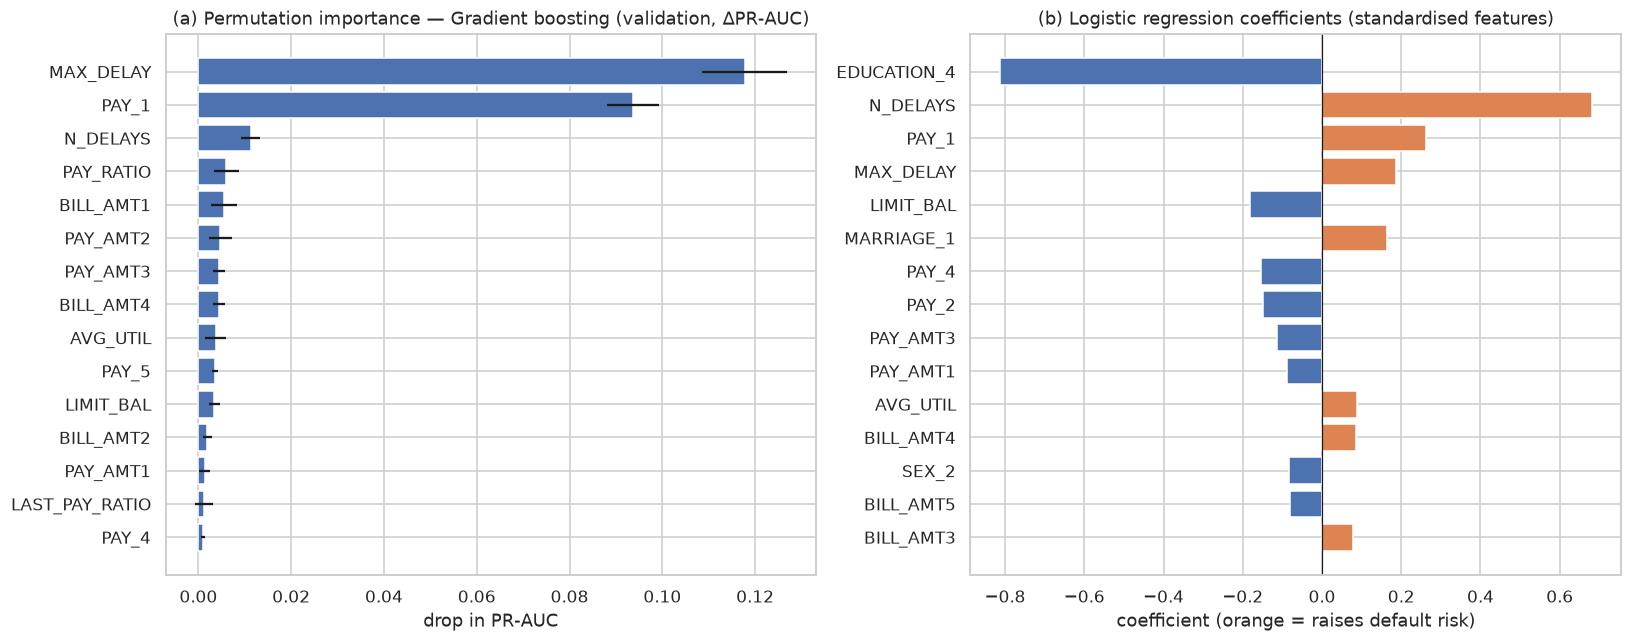

Logistic regression: 4/34 coefficients are exactly zero (L1 part of elastic net).


,mean,std
MAX_DELAY,0.1177,0.0091
PAY_1,0.0936,0.0056
N_DELAYS,0.0112,0.0020
PAY_RATIO,0.0061,0.0027
BILL_AMT1,0.0054,0.0028
PAY_AMT2,0.0047,0.0025
PAY_AMT3,0.0045,0.0013
BILL_AMT4,0.0045,0.0014
AVG_UTIL,0.0038,0.0023
PAY_5,0.0035,0.0006


In [15]:
perm = permutation_importance(best_model, X_val, y_val, scoring="average_precision", n_repeats=10,
                              random_state=SEED, n_jobs=N_JOBS)
imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=X_val.columns)
imp = imp.sort_values("mean", ascending=False)
imp.round(4).to_csv(RES_DIR / "permutation_importance.csv")

lr_best = searches["Logistic regression"].best_estimator_
coef = pd.Series(lr_best.named_steps["clf"].coef_.ravel(), index=FEATURE_NAMES).sort_values(key=abs, ascending=False)
coef.round(4).to_csv(RES_DIR / "logreg_coefficients.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = imp.head(15)[::-1]
axes[0].barh(top.index, top["mean"], xerr=top["std"], color="#4C72B0")
axes[0].set(title=f"(a) Permutation importance — {best_name} (validation, ΔPR-AUC)", xlabel="drop in PR-AUC")
topc = coef.head(15)[::-1]
axes[1].barh(topc.index, topc.values, color=np.where(topc.values > 0, "#DD8452", "#4C72B0"))
axes[1].axvline(0, c="k", lw=.8)
axes[1].set(title="(b) Logistic regression coefficients (standardised features)",
            xlabel="coefficient (orange = raises default risk)")
fig.tight_layout()
save_fig(fig, "fig07_feature_importance")
n_zero = int((coef.abs() < 1e-8).sum())
print(f"Logistic regression: {n_zero}/{len(coef)} coefficients are exactly zero (L1 part of elastic net).")
SUMMARY["perm_importance_top"] = imp.head(8)["mean"].round(4).to_dict()
SUMMARY["logreg_coef_top"] = coef.head(8).round(3).to_dict()
SUMMARY["logreg_zero_coefs"] = n_zero
imp.head(10).round(4)

**Do the importances make sense?** Yes.
* For gradient boosting, the **worst delay** (`MAX_DELAY`) and the **most recent repayment status**
  (`PAY_1`) dominate. Shuffling either one removes about 0.09–0.12 of PR-AUC, while every other
  column contributes less than 0.012. This matches the EDA (Fig. 1b) and credit-scoring practice:
  recent arrears are the strongest predictor of the next default.
* Logistic regression uses the same evidence: `N_DELAYS`, `PAY_1` and `MAX_DELAY` raise the risk,
  and a higher `LIMIT_BAL` lowers it, because the bank gives high limits to clients it already
  trusts. The L1 part of its penalty sets several redundant dummies and payment columns to zero.
* The large negative coefficient for `EDUCATION_4` ("other") comes from a small group (≈ 470
  clients) with only a 7 % default rate. The effect is real in this data but rests on few
  examples, so we would not trust it in deployment.
* The individual `PAY_k` coefficients flip sign (e.g. `PAY_2`, `PAY_4` < 0). This is not a real
  protective effect: the six columns are highly collinear, so the model can trade weight between
  them, and we should not interpret them one by one.

### Error analysis (validation set, chosen threshold)

Confusion matrix (validation):
 [[2244 1261]
 [ 237  758]]


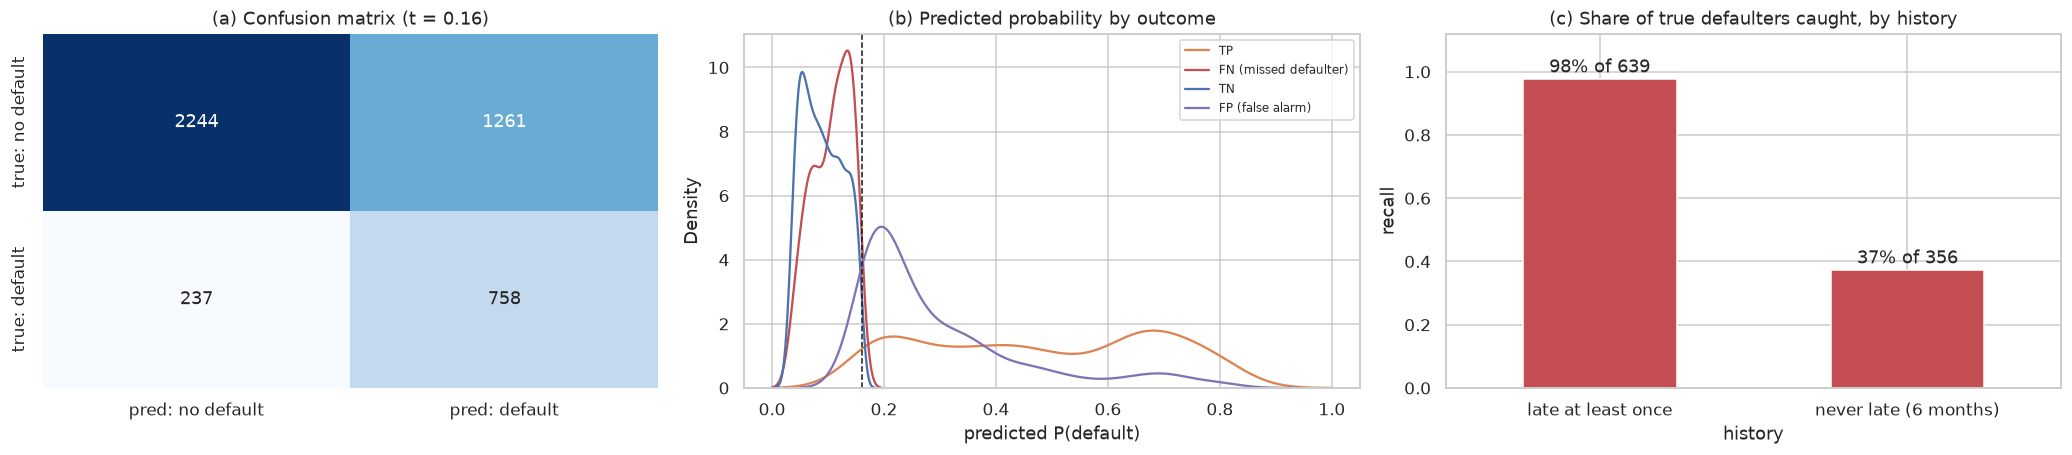

,PAY_1,MAX_DELAY,N_DELAYS,LIMIT_BAL,AVG_UTIL,PAY_RATIO,AGE,p,n
outcome,,,,,,,,,
FN (missed defaulter),0.0,0.0,0.0,160000.0,0.240,0.219,34.0,0.111,237
FP (false alarm),0.0,1.0,1.0,80000.0,0.266,0.079,34.0,0.237,1261
TN,0.0,0.0,0.0,200000.0,0.210,0.171,34.0,0.087,2244
TP,1.0,2.0,2.0,70000.0,0.509,0.052,34.0,0.475,758


,defaulters,recall,non_defaulters,false_alarm_rate
history,,,,
late at least once,639,0.978,811,0.880
never late (6 months),356,0.374,2694,0.203


In [16]:
pred_val = (p_val >= best_thr).astype(int)
ea = X_val.copy()
ea["y"], ea["p"], ea["pred"] = y_val, p_val, pred_val
ea["outcome"] = np.select([(ea.y == 1) & (ea.pred == 1), (ea.y == 0) & (ea.pred == 0),
                           (ea.y == 1) & (ea.pred == 0), (ea.y == 0) & (ea.pred == 1)],
                          ["TP", "TN", "FN (missed defaulter)", "FP (false alarm)"], default="?")
cm = confusion_matrix(y_val, pred_val)
print("Confusion matrix (validation):\n", cm)

# Profile of each outcome group on the most important features
prof_cols = ["PAY_1", "MAX_DELAY", "N_DELAYS", "LIMIT_BAL", "AVG_UTIL", "PAY_RATIO", "AGE"]
profile = ea.groupby("outcome")[prof_cols + ["p"]].median().round(3)
profile["n"] = ea["outcome"].value_counts()
profile.to_csv(RES_DIR / "error_profile.csv")

# Error rate among true defaulters as a function of their recent repayment history
ea["history"] = np.where(ea["N_DELAYS"] == 0, "never late (6 months)", "late at least once")
miss = ea[ea.y == 1].groupby("history").agg(defaulters=("y", "size"), recall=("pred", "mean"))
fa = ea[ea.y == 0].groupby("history").agg(non_defaulters=("y", "size"), false_alarm_rate=("pred", "mean"))
hist_tab = miss.join(fa).round(3)
hist_tab.to_csv(RES_DIR / "error_by_history.csv")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["pred: no default", "pred: default"], yticklabels=["true: no default", "true: default"])
axes[0].set_title(f"(a) Confusion matrix (t = {best_thr:.2f})")
for lbl, c in [("TP", "#DD8452"), ("FN (missed defaulter)", "#C44E52"), ("TN", "#4C72B0"), ("FP (false alarm)", "#8172B3")]:
    sns.kdeplot(ea.loc[ea.outcome == lbl, "p"], ax=axes[1], label=lbl, color=c, clip=(0, 1))
axes[1].axvline(best_thr, c="k", ls="--", lw=1)
axes[1].set(title="(b) Predicted probability by outcome", xlabel="predicted P(default)")
axes[1].legend(fontsize=8)
hist_tab["recall"].plot.bar(ax=axes[2], color="#C44E52", rot=0)
axes[2].set(title="(c) Share of true defaulters caught, by history", ylabel="recall", ylim=(0, 1.12))
for i, (r, n) in enumerate(zip(hist_tab["recall"], hist_tab["defaulters"])):
    axes[2].text(i, r + .02, f"{r:.0%} of {n}", ha="center")
fig.tight_layout()
save_fig(fig, "fig08_error_analysis")

SUMMARY["error_confusion_val"] = cm.tolist()
SUMMARY["error_by_history"] = hist_tab.to_dict(orient="index")
SUMMARY["error_profile"] = profile.to_dict(orient="index")
display(profile)
display(hist_tab)

In [17]:
# The most confident mistakes — what do they look like?
show = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "PAY_3", "N_DELAYS", "BILL_AMT1", "PAY_AMT1", "AVG_UTIL", "p"]
worst_fn = ea[ea.outcome.str.startswith("FN")].nsmallest(6, "p")[show]
worst_fp = ea[ea.outcome.str.startswith("FP")].nlargest(6, "p")[show]
worst_fn.round(3).to_csv(RES_DIR / "worst_false_negatives.csv")
worst_fp.round(3).to_csv(RES_DIR / "worst_false_positives.csv")
print("Defaulters the model was most sure were safe:")
display(worst_fn.round(3))
print("Non-defaulters the model was most sure would default:")
display(worst_fp.round(3))

Defaulters the model was most sure were safe:


,LIMIT_BAL,AGE,PAY_1,PAY_2,PAY_3,N_DELAYS,BILL_AMT1,PAY_AMT1,AVG_UTIL,p
15688,280000,30,0,0,0,0,31272,10000,0.392,0.028
4320,420000,34,-1,-1,-1,0,13207,6222,0.012,0.033
25771,350000,33,0,-1,-1,0,82964,68940,0.119,0.035
11665,200000,34,-1,-1,0,0,12842,13805,0.068,0.036
29293,50000,25,-1,-1,-1,0,9716,25045,0.222,0.037
28182,360000,33,-1,0,0,0,5334,3017,0.123,0.037


Non-defaulters the model was most sure would default:


,LIMIT_BAL,AGE,PAY_1,PAY_2,PAY_3,N_DELAYS,BILL_AMT1,PAY_AMT1,AVG_UTIL,p
13810,40000,47,2,2,2,6,11084,2000,0.324,0.833
4248,90000,42,2,2,2,6,48674,2300,0.579,0.820
8407,50000,28,2,2,2,6,31336,1500,0.656,0.814
1082,60000,30,2,2,2,6,34735,0,0.604,0.812
14708,80000,37,2,2,2,6,57844,2700,0.750,0.808
22459,170000,36,2,2,2,6,15570,0,0.098,0.799


**What the errors tell us.**
* **Missed defaulters (FN) look like good clients.** Their median repayment status is "on time",
  they have no delays in six months, their credit limits are high and their utilisation is moderate.
  Fig. 8c makes the point sharply: among defaulters who were late at least once the model catches
  **98 %**, but among defaulters who were **never late it catches only 37 %**. About **94 % of
  all missed defaulters have a clean six-month record.** Nothing in this history separates them
  from the thousands of clean clients who keep paying. This is a limit of the *features*, not of
  the model: income, other debts or a recent job loss would be needed to catch them.
* The **most confident misses** (table above) are mostly high-limit clients (up to NT$ 420k) who paid in
  full (`PAY = −1`) or revolved normally, with low utilisation. The model gave them a 3 % default
  probability, and on paper they are among the safest customers.
* **False alarms (FP)** come in two kinds. More than half are clients with past delays who
  nevertheless paid in October. With a threshold of 0.16, the model flags 88 % of non-defaulters
  who were ever late. The most confident false alarms were 2 months late in each of the last six
  months and still did not default. The rest are clean clients near the threshold. Under a 5:1 cost
  ratio, flagging risky-looking clients is the economically correct decision, so many false alarms
  are a *deliberate* consequence of the cost-based threshold, not a model failure.
* The predicted probabilities of FN and TN overlap almost completely (Fig. 8b). No threshold can
  separate them, which confirms that better features, not a better threshold, are needed.

## Twist — Imbalance study

**Question.** About 22 % of clients default. How much does this imbalance hurt our models, and which
remedy works best: **re-weighting** the classes, **resampling** the training data (random
oversampling, SMOTE, random undersampling), or simply **moving the decision threshold**? What happens
when defaults become much rarer?

**Setup.**
* **Experiment 1** compares the strategies on the natural data. It uses the two best model types
  from Section E, gradient boosting and logistic regression, each with its tuned hyperparameters.
  Resamplers sit **inside an `imblearn` pipeline**, so only the training folds are resampled and the
  evaluation folds keep the true class distribution. Each strategy is evaluated at the default
  threshold of 0.5 and with a **cost-tuned threshold** (`TunedThresholdClassifierCV`, which picks the
  threshold by an inner 3-fold CV on the training fold only).
* **Experiment 2** artificially lowers the default rate to 10 %, 5 %, 2 % and 1 %, by subsampling
  defaulters in both the training and the validation data, repeated with 5 seeds.

**Metrics** are chosen for imbalance: PR-AUC, ROC-AUC, recall, precision, F2, balanced accuracy,
expected cost and the Brier score (to check how trustworthy the probabilities are).

In [18]:
def best_clf(name):
    """Fresh, unfitted copy of the tuned classifier step of a model."""
    return clone(searches[name].best_estimator_.named_steps["clf"])


def imb_pipe(clf, sampler=None):
    steps = [("prep", make_preprocessor())]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", clf))
    return ImbPipeline(steps)


STRATEGIES = {
    "No remedy": lambda c: imb_pipe(c),
    "Class weights": lambda c: imb_pipe(c.set_params(class_weight="balanced")),
    "Random oversampling": lambda c: imb_pipe(c, RandomOverSampler(random_state=SEED)),
    "SMOTE": lambda c: imb_pipe(c, SMOTE(random_state=SEED)),
    "Random undersampling": lambda c: imb_pipe(c, RandomUnderSampler(random_state=SEED)),
}
TWIST_SCORING = {k: SCORING[k] for k in ["ap", "roc_auc", "recall", "precision", "f2", "bal_acc", "cost"]}
TWIST_SCORING["brier"] = "neg_brier_score"
INNER_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

twist_models = ["Gradient boosting", "Logistic regression"]
imb_rows = []
for mname in twist_models:
    for sname, make in STRATEGIES.items():
        for thr_mode in ["t = 0.5", "cost-tuned t"]:
            est = make(best_clf(mname))
            if thr_mode == "cost-tuned t":
                est = TunedThresholdClassifierCV(est, scoring=cost_scorer, cv=INNER_CV, random_state=SEED)
            res = cross_validate(est, X_train, y_train, cv=CV, scoring=TWIST_SCORING, n_jobs=N_JOBS)
            row = {"model": mname, "strategy": sname, "threshold": thr_mode}
            for k in TWIST_SCORING:
                s = res[f"test_{k}"] * (-1 if k in ("cost", "brier") else 1)
                row[f"{k}_mean"], row[f"{k}_std"] = s.mean(), s.std()
            row["fit_time_s"] = res["fit_time"].mean()
            imb_rows.append(row)
        print(f"done: {mname} / {sname}")
imb = pd.DataFrame(imb_rows)
imb.round(4).to_csv(RES_DIR / "twist_exp1_strategies.csv", index=False)
SUMMARY["twist_exp1"] = imb.round(4).to_dict(orient="records")
imb.pivot_table(index=["model", "strategy"], columns="threshold",
                values=["recall_mean", "precision_mean", "cost_mean"]).round(3)

done: Gradient boosting / No remedy


done: Gradient boosting / Class weights


done: Gradient boosting / Random oversampling


done: Gradient boosting / SMOTE


done: Gradient boosting / Random undersampling


done: Logistic regression / No remedy


done: Logistic regression / Class weights


done: Logistic regression / Random oversampling


done: Logistic regression / SMOTE


done: Logistic regression / Random undersampling


cost_mean         precision_mean  \
threshold                                cost-tuned t t = 0.5   cost-tuned t   
model               strategy                                                   
Gradient boosting   Class weights               0.550   0.565          0.378   
                    No remedy                   0.544   0.755          0.383   
                    Random oversampling         0.549   0.568          0.362   
                    Random undersampling        0.554   0.565          0.382   
                    SMOTE                       0.568   0.685          0.362   
Logistic regression Class weights               0.581   0.583          0.366   
                    No remedy                   0.582   0.814          0.384   
                    Random oversampling         0.586   0.585          0.359   
                    Random undersampling        0.579   0.583          0.370   
                    SMOTE                       0.578   0.590          0.349   

                                                  recall_mean          
threshold                                t = 0.5 cost-tuned t t = 0.5  
model               strategy                                           
Gradient boosting   Class weights          0.462        0.751   0.637  
                    No remedy              0.673        0.751   0.352  
                    Random oversampling    0.472        0.781   0.627  
                    Random undersampling   0.445        0.739   0.653  
                    SMOTE                  0.594        0.752   0.442  
Logistic regression Class weights          0.451        0.729   0.625  
                    No remedy              0.644        0.701   0.297  
                    Random oversampling    0.451        0.737   0.624  
                    Random undersampling   0.448        0.728   0.628  
                    SMOTE                  0.451        0.763   0.617

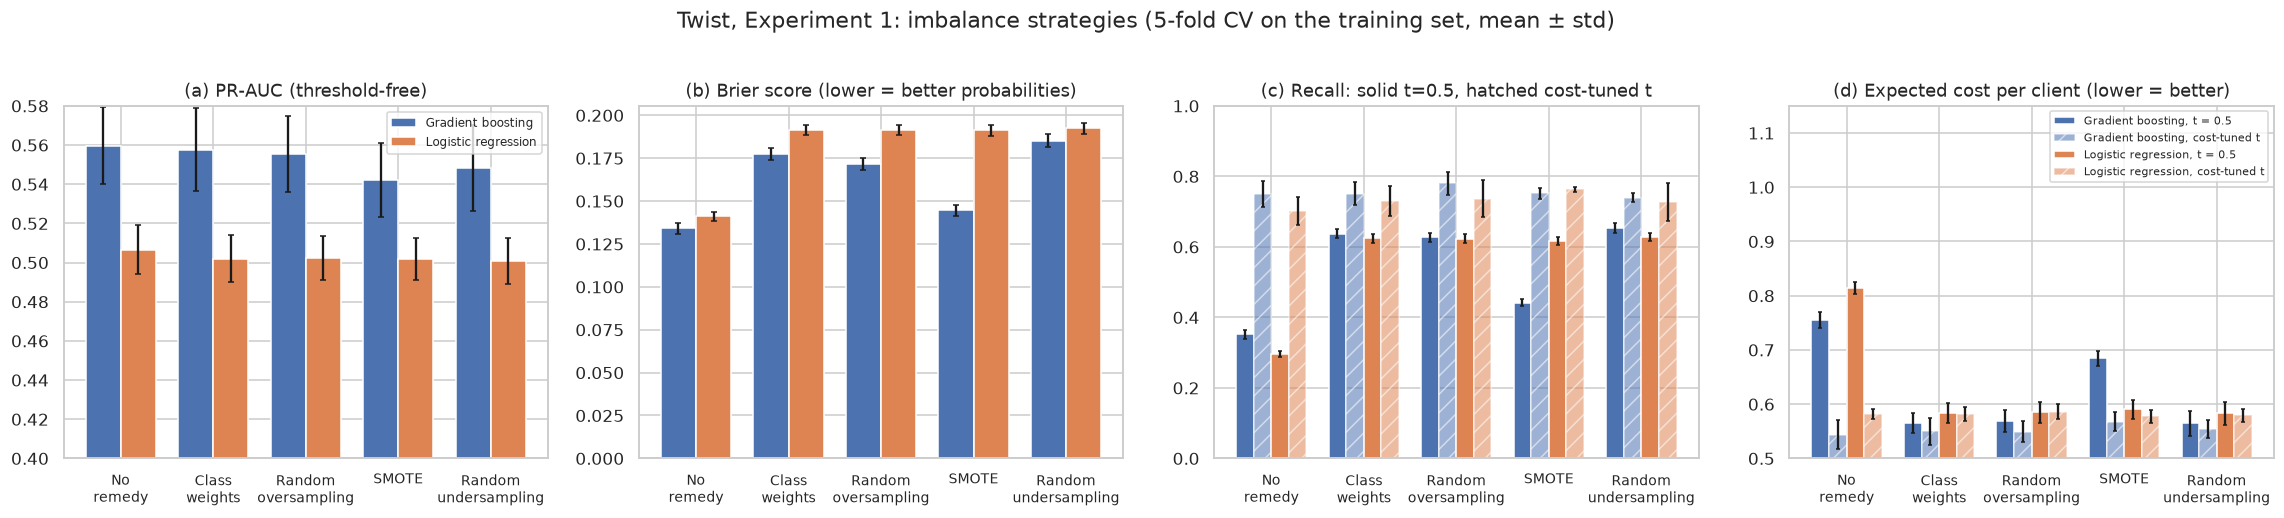

In [19]:
# Figure 9: Experiment 1 — ranking quality is unchanged, decisions change a lot
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
strat_order = list(STRATEGIES)
colors = {"Gradient boosting": "#4C72B0", "Logistic regression": "#DD8452"}
x = np.arange(len(strat_order))
for j, mname in enumerate(twist_models):
    sub = imb[(imb.model == mname) & (imb.threshold == "t = 0.5")].set_index("strategy").loc[strat_order]
    off = (j - .5) * .38
    axes[0].bar(x + off, sub["ap_mean"], .38, yerr=sub["ap_std"], color=colors[mname], label=mname, capsize=2)
    axes[1].bar(x + off, sub["brier_mean"], .38, yerr=sub["brier_std"], color=colors[mname], capsize=2)
    for k, (ax, metric) in enumerate([(axes[2], "recall_mean"), (axes[3], "cost_mean")]):
        for thr_mode, hatch, alpha in [("t = 0.5", "", 1.0), ("cost-tuned t", "//", .55)]:
            s2 = imb[(imb.model == mname) & (imb.threshold == thr_mode)].set_index("strategy").loc[strat_order]
            o2 = off + (-.095 if thr_mode == "t = 0.5" else .095)
            ax.bar(x + o2, s2[metric], .19, yerr=s2[metric.replace("mean", "std")], color=colors[mname],
                   alpha=alpha, hatch=hatch, capsize=1.5,
                   label=f"{mname}, {thr_mode}" if k == 1 else None)
axes[0].set(title="(a) PR-AUC (threshold-free)", ylim=(0.4, 0.58))
axes[1].set(title="(b) Brier score (lower = better probabilities)")
axes[2].set(title="(c) Recall: solid t=0.5, hatched cost-tuned t", ylim=(0, 1))
axes[3].set(title="(d) Expected cost per client (lower = better)", ylim=(0.5, 1.15))
for ax in axes:
    ax.set_xticks(x, [s.replace(" ", "\n") for s in strat_order], fontsize=9)
axes[0].legend(loc="upper right", fontsize=8)
h, l = axes[3].get_legend_handles_labels()
axes[3].legend(h[:4], l[:4], fontsize=7, loc="upper right")
fig.suptitle("Twist, Experiment 1: imbalance strategies (5-fold CV on the training set, mean ± std)", y=1.02)
fig.tight_layout()
save_fig(fig, "fig09_twist_strategies")

### Experiment 2: artificially stronger imbalance

We keep every non-defaulter and randomly keep only enough defaulters to reach a target default rate,
in both the training set and the validation set. This simulates a portfolio where defaults are
rarer, such as prime customers. For each rate and each of 5 seeds we train gradient boosting
(tuned hyperparameters) three ways:
* without any remedy, threshold 0.5;
* with balanced class weights, threshold 0.5;
* without any remedy but with a cost-tuned threshold.

We then evaluate on the equally imbalanced validation subset. The 5 seeds give the variability.

In [20]:
def subsample_to_rate(X, y, rate, rng):
    """Keep all negatives and a random subset of positives so that mean(y) ≈ rate."""
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    n_pos = min(len(pos), int(round(rate * len(neg) / (1 - rate))))
    idx = np.sort(np.concatenate([neg, rng.choice(pos, n_pos, replace=False)]))
    return X.iloc[idx], y[idx]


RATES = [float(round(y_train.mean(), 3)), 0.10, 0.05, 0.02, 0.01]
EXP2_SEEDS = [0, 1, 2, 3, 4]
exp2_rows = []
t0 = time.time()
for rate in RATES:
    for sd in EXP2_SEEDS:
        rng = np.random.default_rng(sd)
        Xtr_r, ytr_r = subsample_to_rate(X_train, y_train, rate, rng)
        Xva_r, yva_r = subsample_to_rate(X_val, y_val, rate, rng)
        variants = {
            "No remedy, t = 0.5": imb_pipe(best_clf("Gradient boosting")),
            "Class weights, t = 0.5": imb_pipe(best_clf("Gradient boosting").set_params(class_weight="balanced")),
            "No remedy, cost-tuned t": TunedThresholdClassifierCV(imb_pipe(best_clf("Gradient boosting")),
                                                             scoring=cost_scorer, cv=INNER_CV, random_state=SEED),
        }
        for vname, est in variants.items():
            est.fit(Xtr_r, ytr_r)
            proba = est.predict_proba(Xva_r)[:, 1]
            thr = getattr(est, "best_threshold_", 0.5)
            m = threshold_metrics(yva_r, proba, thr)
            m["ap_lift"] = m["ap"] / yva_r.mean()
            exp2_rows.append({"rate": rate, "seed": sd, "variant": vname, "threshold_used": thr, **m})
print(f"Experiment 2 finished in {time.time() - t0:.0f}s")
exp2 = pd.DataFrame(exp2_rows)
exp2.round(4).to_csv(RES_DIR / "twist_exp2_rates_raw.csv", index=False)
exp2_sum = exp2.groupby(["rate", "variant"]).agg(["mean", "std"])[
    ["roc_auc", "ap", "ap_lift", "recall", "precision", "bal_acc", "threshold_used"]]
exp2_sum.round(4).to_csv(RES_DIR / "twist_exp2_rates_summary.csv")
SUMMARY["twist_exp2"] = {f"{r}|{v}": {k: [round(float(exp2_sum.loc[(r, v), (k, "mean")]), 4),
                                          round(float(exp2_sum.loc[(r, v), (k, "std")]), 4)]
                                      for k in ["roc_auc", "ap", "ap_lift", "recall", "precision", "bal_acc", "threshold_used"]}
                         for r, v in exp2_sum.index}
exp2_sum.round(3)

Experiment 2 finished in 91s


roc_auc            ap        ap_lift         \
                                 mean    std   mean    std    mean    std   
rate  variant                                                               
0.010 Class weights, t = 0.5    0.755  0.019  0.056  0.005   5.686  0.507   
      No remedy, cost-tuned t   0.765  0.024  0.055  0.011   5.613  1.121   
      No remedy, t = 0.5        0.765  0.024  0.055  0.011   5.613  1.121   
0.020 Class weights, t = 0.5    0.761  0.019  0.115  0.011   5.719  0.526   
      No remedy, cost-tuned t   0.769  0.022  0.122  0.025   6.065  1.251   
      No remedy, t = 0.5        0.769  0.022  0.122  0.025   6.065  1.251   
0.050 Class weights, t = 0.5    0.764  0.018  0.217  0.034   4.356  0.691   
      No remedy, cost-tuned t   0.765  0.018  0.208  0.032   4.180  0.645   
      No remedy, t = 0.5        0.765  0.018  0.208  0.032   4.180  0.645   
0.100 Class weights, t = 0.5    0.784  0.009  0.359  0.019   3.595  0.186   
      No remedy, cost-tuned t   0.784  0.010  0.360  0.025   3.599  0.247   
      No remedy, t = 0.5        0.784  0.010  0.360  0.025   3.599  0.247   
0.221 Class weights, t = 0.5    0.787  0.001  0.567  0.001   2.566  0.006   
      No remedy, cost-tuned t   0.787  0.001  0.568  0.003   2.570  0.012   
      No remedy, t = 0.5        0.787  0.001  0.568  0.003   2.570  0.012   

                              recall        precision        bal_acc         \
                                mean    std      mean    std    mean    std   
rate  variant                                                                 
0.010 Class weights, t = 0.5   0.537  0.024     0.040  0.008   0.702  0.020   
      No remedy, cost-tuned t  0.000  0.000     0.000  0.000   0.500  0.000   
      No remedy, t = 0.5       0.000  0.000     0.000  0.000   0.500  0.000   
0.020 Class weights, t = 0.5   0.572  0.030     0.069  0.009   0.706  0.013   
      No remedy, cost-tuned t  0.097  0.091     0.218  0.098   0.545  0.042   
      No remedy, t = 0.5       0.000  0.000     0.000  0.000   0.500  0.000   
0.050 Class weights, t = 0.5   0.585  0.045     0.146  0.013   0.703  0.024   
      No remedy, cost-tuned t  0.296  0.060     0.315  0.021   0.631  0.028   
      No remedy, t = 0.5       0.005  0.009     0.181  0.262   0.503  0.005   
0.100 Class weights, t = 0.5   0.617  0.016     0.269  0.014   0.715  0.011   
      No remedy, cost-tuned t  0.499  0.050     0.371  0.032   0.702  0.020   
      No remedy, t = 0.5       0.096  0.021     0.559  0.044   0.544  0.010   
0.221 Class weights, t = 0.5   0.627  0.004     0.477  0.003   0.716  0.002   
      No remedy, cost-tuned t  0.753  0.029     0.377  0.022   0.699  0.007   
      No remedy, t = 0.5       0.352  0.004     0.719  0.004   0.657  0.002   

                              threshold_used         
                                        mean    std  
rate  variant                                        
0.010 Class weights, t = 0.5           0.500  0.000  
      No remedy, cost-tuned t          0.213  0.024  
      No remedy, t = 0.5               0.500  0.000  
0.020 Class weights, t = 0.5           0.500  0.000  
      No remedy, cost-tuned t          0.181  0.053  
      No remedy, t = 0.5               0.500  0.000  
0.050 Class weights, t = 0.5           0.500  0.000  
      No remedy, cost-tuned t          0.175  0.019  
      No remedy, t = 0.5               0.500  0.000  
0.100 Class weights, t = 0.5           0.500  0.000  
      No remedy, cost-tuned t          0.171  0.015  
      No remedy, t = 0.5               0.500  0.000  
0.221 Class weights, t = 0.5           0.500  0.000  
      No remedy, cost-tuned t          0.163  0.013  
      No remedy, t = 0.5               0.500  0.000

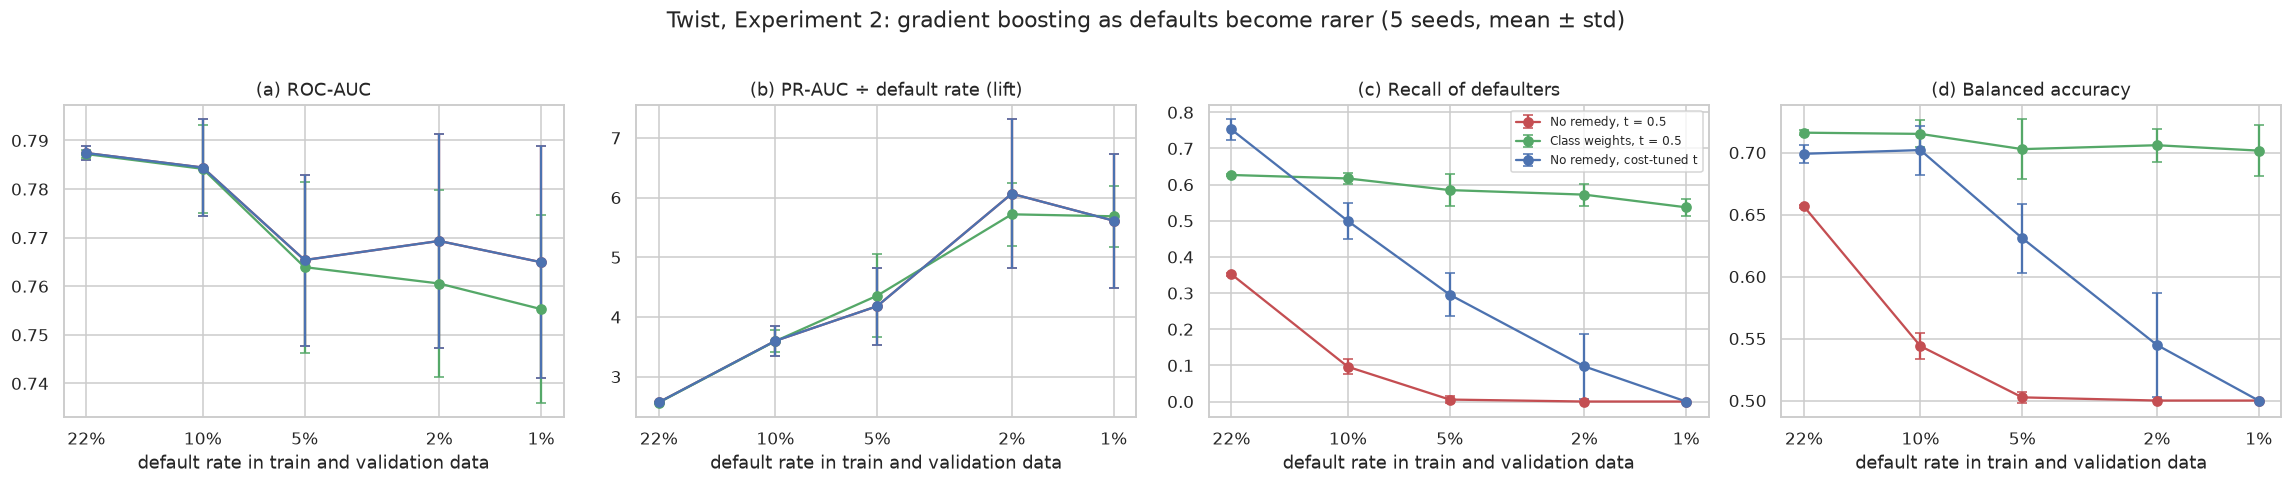

In [21]:
# Figure 10: Experiment 2
fig, axes = plt.subplots(1, 4, figsize=(21, 4.3))
vcol = {"No remedy, t = 0.5": "#C44E52", "Class weights, t = 0.5": "#55A868", "No remedy, cost-tuned t": "#4C72B0"}
for vname, c in vcol.items():
    s = exp2[exp2.variant == vname].groupby("rate")
    for ax, metric in zip(axes, ["roc_auc", "ap_lift", "recall", "bal_acc"]):
        mu, sd_ = s[metric].mean(), s[metric].std()
        ax.errorbar(mu.index, mu.values, yerr=sd_.values, marker="o", c=c, label=vname, capsize=3)
for ax, t in zip(axes, ["(a) ROC-AUC", "(b) PR-AUC ÷ default rate (lift)", "(c) Recall of defaulters",
                        "(d) Balanced accuracy"]):
    ax.set(title=t, xscale="log", xlabel="default rate in train and validation data")
    ax.set_xticks(RATES, [f"{r:.0%}" if r >= 0.02 else f"{r:.0%}" for r in RATES])
    ax.invert_xaxis()
axes[2].legend(fontsize=8)
fig.suptitle("Twist, Experiment 2: gradient boosting as defaults become rarer (5 seeds, mean ± std)", y=1.02)
fig.tight_layout()
save_fig(fig, "fig10_twist_rates")

**Twist conclusions.**
1. **Re-weighting and resampling do not improve how well the model ranks clients. SMOTE even
   hurts it.** For gradient boosting, PR-AUC is 0.560 without a remedy, 0.558 with class weights,
   0.555 with oversampling, 0.548 with undersampling and **0.542 with SMOTE** (Fig. 9a). SMOTE
   interpolates one-hot and ordinal delay codes into values that never occur in the real data.
   The main effect of every remedy is to **push the predicted probabilities upwards**, which works
   like lowering the threshold. The price is **miscalibrated probabilities**: the Brier score rises
   from 0.134 to 0.17–0.19 (Fig. 9b).
2. **Simply moving the threshold is the best remedy.** With no remedy and a cost-tuned threshold,
   gradient boosting reaches recall 0.75 and the **lowest expected cost (0.544 ± 0.027)**. Every
   reweighting or resampling variant costs between 0.549 and 0.685 (Fig. 9c–d). Threshold tuning
   also keeps calibrated probabilities and needs no synthetic data. Once the threshold is tuned,
   all strategies end up at about the same cost, so the remedies were only ever moving the threshold.
   The tuned threshold (≈ 0.16) is very close to the Bayes-optimal 1/6, which shows that the
   unweighted model's probabilities are already nearly calibrated.
3. **As defaults become rarer (Experiment 2), the ranking survives but the decision rule breaks.**
   ROC-AUC only falls from 0.79 to ≈ 0.76–0.77, and the PR-AUC lift over chance *rises* to about
   5–6×. Meanwhile recall at threshold 0.5 collapses from 0.35 to **0** at a 5 % default rate,
   because the model never predicts "default".
4. **Which remedy is "right" at extreme imbalance depends on the costs.** At a 1–2 % default rate,
   the cost-optimal threshold flags almost **nobody**. The model cannot reach the precision above
   1/6 that would justify a flag when a miss costs only 5× a false alarm. Class weights keep
   recall at ≈ 0.55 and balanced accuracy at ≈ 0.70, but with only **4 % precision**, about 24
   false alarms per defaulter caught, and three times the expected cost (0.156 vs 0.049). Balanced
   class weights silently assume a cost ratio equal to the class ratio (99:1 at a 1 % default
   rate). That is only correct if a missed default really is that expensive.

**Take-away:** imbalance mainly damages the *decision rule*, not the *learned ranking*. The cleanest
fix is to keep the probabilities honest and choose the threshold from the real business costs.
For deployment we therefore keep the **unweighted** model with the **cost-tuned threshold** chosen
on the validation set.

## Final evaluation on the test set (used exactly once)

The final model is the tuned **best model from Section E**, trained on the training set, with the
**cost-optimal threshold chosen on the validation set**. Nothing below feeds back into any
decision. We also report 95 % bootstrap confidence intervals (1,000 resamples of the test
predictions) to show how much the test estimates would vary.

In [22]:
p_test = best_model.predict_proba(X_test)[:, 1]
test_m = threshold_metrics(y_test, p_test, best_thr)
test_m_05 = threshold_metrics(y_test, p_test, 0.5)
base_lr = baselines["Logistic regression (default)"].fit(X_train, y_train)
test_base = threshold_metrics(y_test, base_lr.predict_proba(X_test)[:, 1], 0.5)

rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    boot.append(threshold_metrics(y_test[idx], p_test[idx], best_thr))
boot = pd.DataFrame(boot)
final = pd.DataFrame({
    f"{best_name}, t = {best_thr:.2f}": test_m,
    "95% CI low": boot.quantile(0.025),
    "95% CI high": boot.quantile(0.975),
    f"{best_name}, t = 0.5": test_m_05,
    "Baseline: plain LR, t = 0.5": test_base,
}).round(4)
final.to_csv(RES_DIR / "final_test_results.csv")
SUMMARY["test"] = final.to_dict()
SUMMARY["test_confusion"] = confusion_matrix(y_test, (p_test >= best_thr).astype(int)).tolist()
print("Test confusion matrix:\n", SUMMARY["test_confusion"])
final

Test confusion matrix:
 [[2203, 1302], [250, 745]]


,"Gradient boosting, t = 0.16",95% CI low,95% CI high,"Gradient boosting, t = 0.5","Baseline: plain LR, t = 0.5"
ap,0.5700,0.5371,0.6026,0.5700,0.5072
roc_auc,0.7813,0.7647,0.7976,0.7813,0.7495
recall,0.7487,0.7218,0.7723,0.3558,0.2925
precision,0.3639,0.3437,0.3846,0.6834,0.6410
f1,0.4898,0.4680,0.5111,0.4679,0.4017
f2,0.6181,0.5952,0.6387,0.3935,0.3281
bal_acc,0.6886,0.6725,0.7027,0.6545,0.6230
cost,0.5671,0.5364,0.6024,0.7487,0.8184
brier,0.1331,0.1268,0.1402,0.1331,0.1416


In [23]:
with open(RES_DIR / "summary.json", "w") as f:
    json.dump(SUMMARY, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved results/summary.json")

Saved results/summary.json


## G. Conclusion

The full discussion is in the report (`report/report.pdf`). In short:
* **Deploy** the tuned **gradient-boosting** model with the cost-based threshold t = 0.16.
  * **Performance:** on the untouched test set it reaches PR-AUC 0.57 and ROC-AUC 0.78. At the
    chosen threshold it catches about 75 % of defaulters and cuts the expected cost per client by
    31 % compared with the plain logistic-regression baseline (0.567 vs 0.818).
  * **Stability:** it is tied with the random forest in CV (fold std ≈ 0.02).
  * **Training cost:** it trains about 7× faster than the random forest.
  * **Interpretability:** permutation importance shows it relies on sensible evidence (recent and
    worst delays).
  * If a regulator demands a transparent scorecard, the elastic-net **logistic regression** is the
    fallback. It gives up ≈ 0.05 PR-AUC but every coefficient can be explained.
* **Limitations:**
  * The data come from one Taiwanese bank in 2005, during a credit-card debt crisis, so the results
    may not transfer to other times or places.
  * The 5:1 cost ratio is an assumption.
  * About 94 % of missed defaulters have a clean repayment history, so no model built on these
    features can catch them.
  * Fairness across sex and age was not analysed beyond descriptive rates.
  * The final model was trained on the training set only, not on train + validation, so that the
    validation-chosen threshold stays valid.